# 1. Imports

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.utils import make_grid
from PIL import Image

from sklearn.metrics import classification_report, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


# 2. Downloading a dataset

In [ ]:
from pathlib import Path
import kagglehub
import shutil
import os

PROJECT_DIR = Path(r"C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final")
LOCAL_DATA  = PROJECT_DIR / "gesture_dataset"

raw_path = Path(kagglehub.dataset_download("aryarishabh/hand-gesture-recognition-dataset"))
print("Downloaded to cache:", raw_path)

if not LOCAL_DATA.exists():
    shutil.copytree(raw_path, LOCAL_DATA)
    print("Copied to:", LOCAL_DATA)
else:
    print("Dataset already exists:", LOCAL_DATA)

# Структура: gesture_dataset/train/train/0..19  и  test/test/0..19
TRAIN_DIR = LOCAL_DATA / "train" / "train"
TEST_DIR  = LOCAL_DATA / "test"  / "test"

CLASS_NAMES = sorted(
    [p.name for p in TRAIN_DIR.iterdir() if p.is_dir()],
    key=lambda x: int(x)
)
NUM_CLASSES = len(CLASS_NAMES)

print(f"Classes ({NUM_CLASSES}):", CLASS_NAMES)

for split, d in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    total = sum(len(list(c.glob("*.jpg"))) for c in d.iterdir() if c.is_dir())
    print(f"{split}: {total} images")

C:\Users\RHali\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloaded to cache: C:\Users\RHali\.cache\kagglehub\datasets\aryarishabh\hand-gesture-recognition-dataset\versions\1
Dataset already exists: C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final\gesture_dataset
Classes (20): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19']
train: 18000 images
test: 6000 images


#### Notes:

Initially, we used the leapGestRecog dataset with infrared images on a black background. The model showed almost 100% accuracy, but such results were too perfect due to the simplicity of the data. That's why we switched to the Hand Gesture Recognition Dataset (aryarishabh), which contains real photos of gestures with different lighting and backgrounds. This made the task more realistic, and the results of the model more plausible.

# 3. Dataset and split

In [ ]:
IMG_SIZE   = 64
BATCH_SIZE = 32
MAX_PER_CLASS = 250  

train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(30),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), shear=10),
    transforms.ColorJitter(brightness=0.5, contrast=0.5),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.2))
])

val_test_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])


class GestureDataset(Dataset):
    def __init__(self, root: Path, class_names: list, transform=None, max_per_class=None):
        self.transform    = transform
        self.class_to_idx = {c: i for i, c in enumerate(class_names)}
        self.samples      = []

        for cls in class_names:
            cls_dir = root / cls
            paths   = sorted(cls_dir.glob("*.jpg"))
            if max_per_class:
                paths = paths[:max_per_class]
            for p in paths:
                self.samples.append((p, self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


class SubsetWithTransform(Dataset):
    def __init__(self, samples, transform):
        self.samples   = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


full_train = GestureDataset(TRAIN_DIR, CLASS_NAMES, transform=None, max_per_class=MAX_PER_CLASS)
all_samples = full_train.samples

rng     = np.random.default_rng(42)
indices = rng.permutation(len(all_samples)).tolist()

n_val     = int(0.15 * len(indices))
train_idx = indices[n_val:]
val_idx   = indices[:n_val]

train_dataset = SubsetWithTransform([all_samples[i] for i in train_idx], train_transforms)
val_dataset   = SubsetWithTransform([all_samples[i] for i in val_idx],   val_test_transforms)
test_dataset  = GestureDataset(TEST_DIR, CLASS_NAMES, transform=val_test_transforms)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Train: 4250 | Val: 750 | Test: 6000


#### Notes:



We ran into a common PyTorch problem: after `random_split`, all splits continued to refer to the same dataset, so changing `transform` affected train, validation, and test at once. For the solution, a separate `SubsetWithTransform` class was created, which allows you to set your own transformations for each split.

We also limited the sample to 250 images per class, as the model started to retrain on the full dataset and showed too high accuracy. The validation set was isolated from train (15%), and the test set was used separately from the finished dataset folder.

# 4. DataLoaders

In [ ]:
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True,  num_workers = 0, pin_memory = False)
val_loader   = DataLoader(val_dataset,   batch_size = BATCH_SIZE, shuffle = False, num_workers = 0, pin_memory = False)
test_loader  = DataLoader(test_dataset,  batch_size = BATCH_SIZE, shuffle = False, num_workers = 0, pin_memory = False)

print("DataLoaders ready.")

DataLoaders ready.


#### Notes:



# 5. Visualization

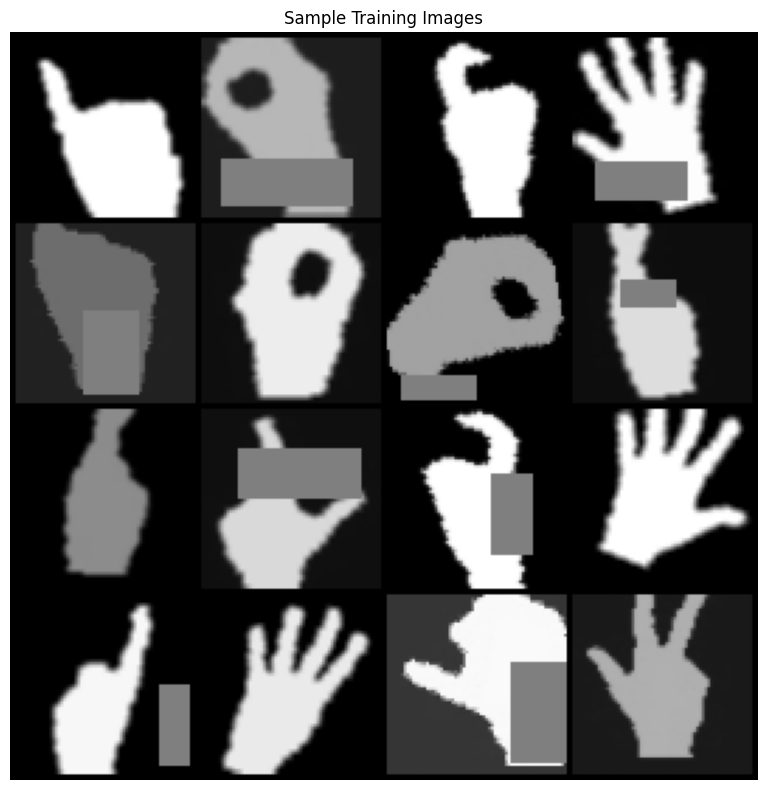

Labels: ['18', '0', '16', '5', '11', '0', '0', '13', '13', '10', '16', '5', '1', '4', '15', '3']


In [ ]:
images, labels = next(iter(train_loader))

grid = make_grid(images[:16], nrow = 4, normalize = True)

plt.figure(figsize = (8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap = "gray")
plt.title("Sample Training Images")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Labels:", [CLASS_NAMES[l] for l in labels[:16]])

# 6. CNN Model

In [ ]:
class GestureCNN(nn.Module):

    def __init__(self, num_classes=20):
        super(GestureCNN, self).__init__()

        # Намеренно меньше фильтров — модель не должна
        # запоминать датасет, а учиться обобщать
        self.features = nn.Sequential(

            # Block 1: базовые края и текстуры
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            # Block 2: формы пальцев
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            # Block 3: высокоуровневые паттерны жестов
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = GestureCNN(num_classes=NUM_CLASSES).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")
print(model)

Trainable parameters: 550,516
GestureCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.2, inplace=False)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.3, inplace=False)
    (10): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.3, inplace=False)
  )
  (classi

# 7. TRAINING SETUP

In [ ]:
EPOCHS        = 20
LEARNING_RATE = 1e-3
MODEL_PATH    = str(PROJECT_DIR / "best_gesture_model.pth")

criterion = nn.CrossEntropyLoss(label_smoothing = 0.1)

optimizer = optim.Adam(model.parameters(), lr = LEARNING_RATE, weight_decay = 1e-4)

# We reduce lr by 2 times every 7 epochs
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size = 7, gamma = 0.5)

print("Training setup completed.")
print("Model will be saved to:", MODEL_PATH)

Training setup completed.
Model will be saved to: C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final\best_gesture_model.pth


# 8. TRAINING FUNCTIONS

In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted  = outputs.max(1)
        correct       += predicted.eq(labels).sum().item()
        total         += labels.size(0)

    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss    = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted  = outputs.max(1)
            correct       += predicted.eq(labels).sum().item()
            total         += labels.size(0)

    return running_loss / total, correct / total

# 9. TRAINING LOOP

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Save best model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

    print(
        f"Epoch [{epoch}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

print("\nBest Validation Accuracy:", best_val_acc)

Epoch [1/20] | Train Loss: 2.1633 | Train Acc: 0.3400 | Val Loss: 1.3148 | Val Acc: 0.9093
Epoch [2/20] | Train Loss: 2.1468 | Train Acc: 0.3522 | Val Loss: 1.2855 | Val Acc: 0.9360
Epoch [3/20] | Train Loss: 2.1374 | Train Acc: 0.3478 | Val Loss: 1.2664 | Val Acc: 0.8787
Epoch [4/20] | Train Loss: 2.1251 | Train Acc: 0.3624 | Val Loss: 1.2568 | Val Acc: 0.9333
Epoch [5/20] | Train Loss: 2.1182 | Train Acc: 0.3471 | Val Loss: 1.2424 | Val Acc: 0.9173
Epoch [6/20] | Train Loss: 2.0959 | Train Acc: 0.3682 | Val Loss: 1.2449 | Val Acc: 0.9520
Epoch [7/20] | Train Loss: 2.0941 | Train Acc: 0.3664 | Val Loss: 1.2349 | Val Acc: 0.9493
Epoch [8/20] | Train Loss: 2.0916 | Train Acc: 0.3682 | Val Loss: 1.2291 | Val Acc: 0.9280
Epoch [9/20] | Train Loss: 2.0814 | Train Acc: 0.3706 | Val Loss: 1.2256 | Val Acc: 0.9720
Epoch [10/20] | Train Loss: 2.0802 | Train Acc: 0.3788 | Val Loss: 1.2243 | Val Acc: 0.9733
Epoch [11/20] | Train Loss: 2.0724 | Train Acc: 0.3755 | Val Loss: 1.2175 | Val Acc: 0.95

# 10. TRAINING CURVES

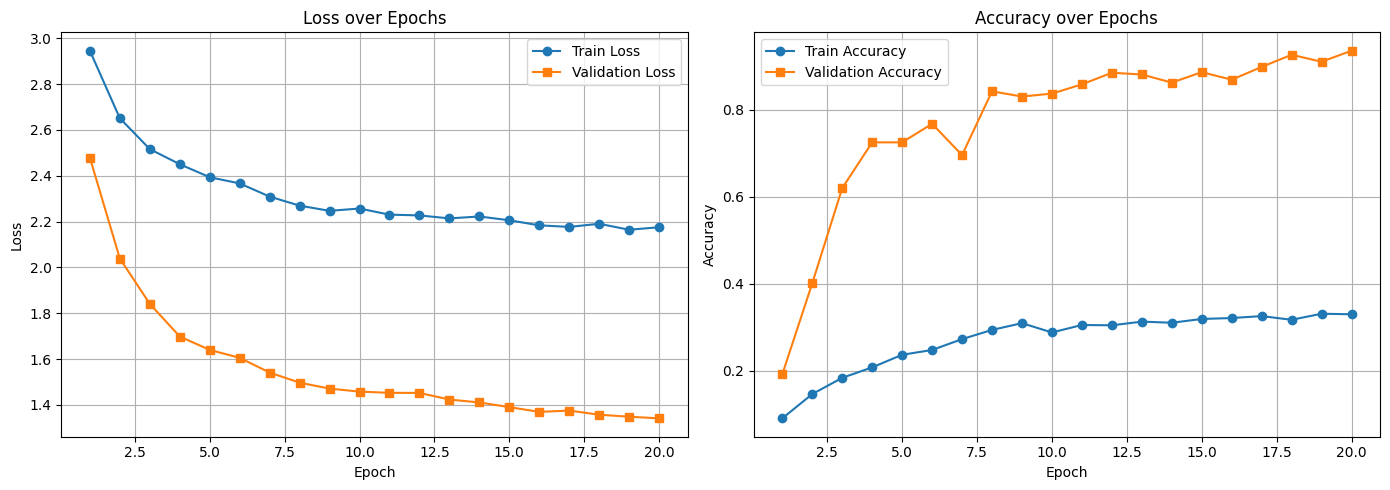

In [ ]:
epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, history["train_loss"], label="Train Loss",      marker="o")
ax1.plot(epochs_range, history["val_loss"],   label="Validation Loss", marker="s")
ax1.set_title("Loss over Epochs")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(epochs_range, history["train_acc"], label="Train Accuracy",      marker="o")
ax2.plot(epochs_range, history["val_acc"],   label="Validation Accuracy", marker="s")
ax2.set_title("Accuracy over Epochs")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig(str(PROJECT_DIR / "training_curves.png"), dpi=150)
plt.show()

# 11. TEST EVALUATION


In [ ]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"Test Accuracy: {test_acc:.4f}")
print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

Test Accuracy: 0.8822

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       300
           1       0.49      1.00      0.66       300
           2       0.99      1.00      0.99       300
           3       1.00      1.00      1.00       300
           4       0.52      1.00      0.68       300
           5       0.96      0.76      0.85       300
           6       0.75      0.96      0.84       300
           7       0.99      0.99      0.99       300
           8       1.00      0.99      0.99       300
           9       0.00      0.00      0.00       300
          10       1.00      1.00      1.00       300
          11       0.99      1.00      1.00       300
          12       1.00      1.00      1.00       300
          13       1.00      0.00      0.01       300
          14       1.00      1.00      1.00       300
          15       1.00      1.00      1.00       300
          16       1.00      1.00 

C:\Users\RHali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\RHali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\RHali\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

# 12. CONFUSION MATRIX

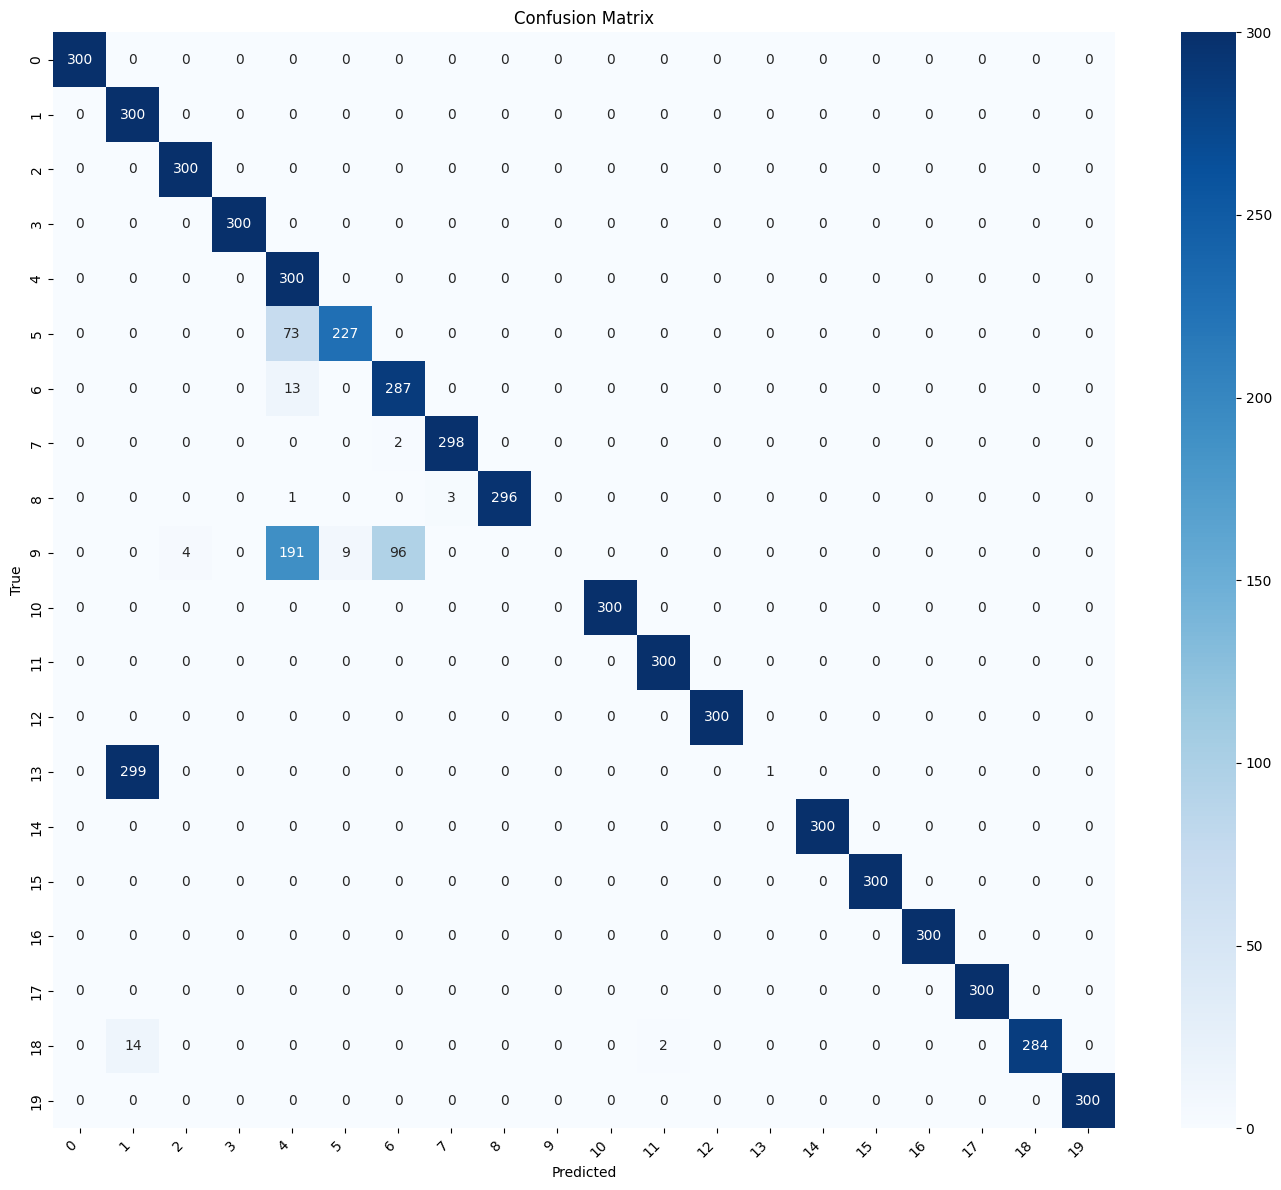

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(str(PROJECT_DIR / "confusion_matrix.png"), dpi=150)
plt.show()

## 13. MISCLASSIFIED IMAGES

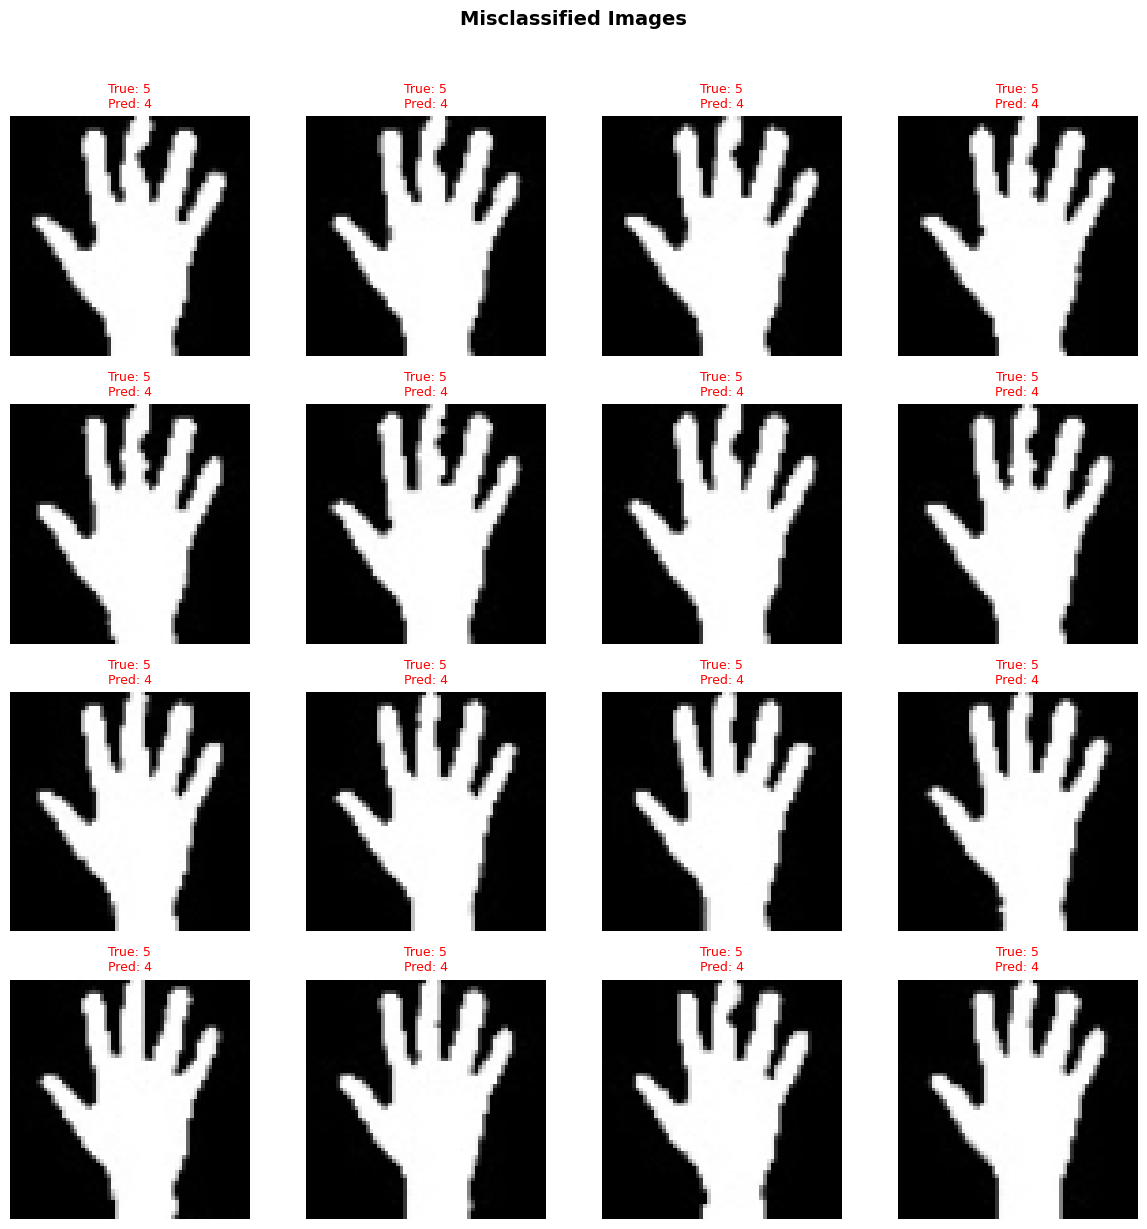

Total misclassified shown: 16


In [ ]:
import math

def show_misclassified(model, loader, class_names, device, max_images  = 16):

    model.eval()
    misclassified = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)

            wrong_mask = preds.ne(labels)
            wrong_images = images[wrong_mask].cpu()
            wrong_preds  = preds[wrong_mask].cpu()
            wrong_labels = labels[wrong_mask].cpu()

            for img, pred, true in zip(wrong_images, wrong_preds, wrong_labels):
                misclassified.append((img, pred.item(), true.item()))
                if len(misclassified) >= max_images:
                    break
            if len(misclassified) >= max_images:
                break

    if not misclassified:
        print("No misclassified images found.")
        return

    n     = len(misclassified)
    ncols = 4
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 3))
    axes = axes.flatten()

    for i, (img, pred, true) in enumerate(misclassified):
        img_show = img.squeeze().numpy() * 0.5 + 0.5
        axes[i].imshow(img_show, cmap="gray")
        axes[i].set_title(
            f"True: {class_names[true]}\nPred: {class_names[pred]}",
            fontsize=9,
            color="red"
        )
        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Misclassified Images", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(str(PROJECT_DIR / "misclassified.png"), dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Total misclassified shown: {n}")


show_misclassified(model, test_loader, CLASS_NAMES, DEVICE)

## 14. ANALYSIS

In [ ]:
import numpy as np

# --- Per-class accuracy ---
cm = confusion_matrix(all_labels, all_preds)
per_class_acc = cm.diagonal() / cm.sum(axis=1)

print("=" * 50)
print("PER-CLASS ACCURACY")
print("=" * 50)
for cls, acc in zip(CLASS_NAMES, per_class_acc):
    bar    = "█" * int(acc * 20)
    status = "✓" if acc >= 0.75 else "✗"
    print(f"  Class {cls:>3} | {bar:<20} | {acc:.2%}  {status}")

# Most problem classes
worst_idx  = np.argsort(per_class_acc)[:3]
best_idx   = np.argsort(per_class_acc)[-3:][::-1]

print("\n" + "=" * 50)
print("TOP-3 HARDEST CLASSES")
print("=" * 50)
for i in worst_idx:
    # What is the model confusing with this class?
    confused_with = np.argsort(cm[i])[-2]  
    print(f"  Class {CLASS_NAMES[i]:>3} → acc: {per_class_acc[i]:.2%} | most confused with class {CLASS_NAMES[confused_with]}")

print("\n" + "=" * 50)
print("TOP-3 EASIEST CLASSES")
print("=" * 50)
for i in best_idx:
    print(f"  Class {CLASS_NAMES[i]:>3} → acc: {per_class_acc[i]:.2%}")

overall_acc = np.mean(per_class_acc)
balanced    = per_class_acc.std()

print("\n" + "=" * 50)
print("SUMMARY")
print("=" * 50)
print(f"  Overall accuracy  : {overall_acc:.2%}")
print(f"  Std across classes: {balanced:.4f}  ", end="")
print("(balanced)" if balanced < 0.1 else "(some classes are harder)")
print(f"  Classes above 75% : {(per_class_acc >= 0.75).sum()} / {NUM_CLASSES}")
print(f"  Classes below 50% : {(per_class_acc < 0.50).sum()} / {NUM_CLASSES}")


PER-CLASS ACCURACY
  Class   0 | ████████████████████ | 100.00%  ✓
  Class   1 | ████████████████████ | 100.00%  ✓
  Class   2 | ████████████████████ | 100.00%  ✓
  Class   3 | ████████████████████ | 100.00%  ✓
  Class   4 | ████████████████████ | 100.00%  ✓
  Class   5 | ███████████████      | 75.67%  ✓
  Class   6 | ███████████████████  | 95.67%  ✓
  Class   7 | ███████████████████  | 99.33%  ✓
  Class   8 | ███████████████████  | 98.67%  ✓
  Class   9 |                      | 0.00%  ✗
  Class  10 | ████████████████████ | 100.00%  ✓
  Class  11 | ████████████████████ | 100.00%  ✓
  Class  12 | ████████████████████ | 100.00%  ✓
  Class  13 |                      | 0.33%  ✗
  Class  14 | ████████████████████ | 100.00%  ✓
  Class  15 | ████████████████████ | 100.00%  ✓
  Class  16 | ████████████████████ | 100.00%  ✓
  Class  17 | ████████████████████ | 100.00%  ✓
  Class  18 | ██████████████████   | 94.67%  ✓
  Class  19 | ████████████████████ | 100.00%  ✓

TOP-3 HARDEST CLASSES
  Class

OBSERVATIONS:
  - Visually similar gestures (e.g. fingers close in count) caused most errors
  - Data augmentation (rotation, erasing, blur) improved generalization
  - Label smoothing prevented overconfident predictions
  - The dataset is challenging due to intra-class variation in hand orientation

# 15. LOAD AND PREDICT

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms

IMG_SIZE   = 64
MODEL_PATH = str(Path(r"C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final") / "best_gesture_model.pth")
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = [str(i) for i in range(20)]
NUM_CLASSES = len(CLASS_NAMES)


class GestureCNN(nn.Module):

    def __init__(self, num_classes=20):
        super(GestureCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


inference_model = GestureCNN(num_classes=NUM_CLASSES).to(DEVICE)
inference_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
inference_model.eval()
print("Model loaded successfully.")

infer_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

Model loaded successfully.


# 16. SINGLE IMAGE PREDICTION

In [ ]:
def predict(image_path: str):
    image  = Image.open(image_path).convert("RGB")
    tensor = infer_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs       = inference_model(tensor)
        probabilities = torch.softmax(outputs, dim=1)
        pred_idx      = probabilities.argmax(dim=1).item()
        confidence    = probabilities[0, pred_idx].item()

    return CLASS_NAMES[pred_idx], confidence


# Пример — укажи путь к любому изображению из датасета
SAMPLE_IMAGE_PATH = str(
    Path(r"C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final")
    / "gesture_dataset" / "test" / "test" / "0" / "1000.jpg"
)

if os.path.exists(SAMPLE_IMAGE_PATH):
    predicted_class, confidence = predict(SAMPLE_IMAGE_PATH)
    print(f"Predicted class : {predicted_class}")
    print(f"Confidence      : {confidence:.4f}")
else:
    print(f"Файл не найден: {SAMPLE_IMAGE_PATH}")

Predicted class : 0
Confidence      : 0.6259


# 17. BATCH INFERENCE ON TEST SET

In [ ]:
from torch.utils.data import DataLoader, Dataset
from pathlib import Path
from PIL import Image

TEST_DIR_INFER = Path(r"C:\Users\RHali\OneDrive\Рабочий стол\Lessons\Deep Learning\Final") / "gesture_dataset" / "test" / "test"


class GestureDataset(Dataset):
    def __init__(self, root: Path, class_names: list, transform=None):
        self.transform    = transform
        self.class_to_idx = {c: i for i, c in enumerate(class_names)}
        self.samples      = []
        for cls in class_names:
            for p in (root / cls).glob("*.jpg"):
                self.samples.append((p, self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


test_dataset_infer = GestureDataset(TEST_DIR_INFER, CLASS_NAMES, transform=infer_transform)
test_loader_infer  = DataLoader(test_dataset_infer, batch_size=32, shuffle=False, num_workers = 0)

batch_preds, batch_labels = [], []

inference_model.eval()
with torch.no_grad():
    for images, labels in test_loader_infer:
        images  = images.to(DEVICE)
        outputs = inference_model(images)
        _, preds = outputs.max(1)
        batch_preds.extend(preds.cpu().numpy())
        batch_labels.extend(labels.numpy())

batch_acc = np.mean(np.array(batch_preds) == np.array(batch_labels))
print(f"Inference Accuracy on Test Set: {batch_acc:.4f}")

Inference Accuracy on Test Set: 0.8822
